# Experiment No. 2 B (Group A)

**Aim:**  
Use the diabetes data set from UCI and Pima Indians Diabetes data set for performing the following:  
a. Univariate analysis: Frequency, Mean, Median, Mode, Variance, Standard Deviation, Skewness and Kurtosis  
b. Bivariate analysis: Linear and logistic regression modeling  
c. Multiple Regression analysis  
d. Also compare the results of the above analysis for the two data sets  

**Dataset Link:** `https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv`

**Objectives:**  
1. Load and inspect the Pima Indians Diabetes dataset using URL.
2. Perform comprehensive Univariate Analysis for all variables.
3. Perform Bivariate Analysis via Linear Regression and Logistic Regression modeling and extract coefficients.
4. Perform Multiple Regression analysis using Statsmodels OLS and display statistical summary.
5. Generate Correlation Matrix Heatmap and Scatterplot Matrix visualizations.
6. Compare analytical results and regression performance between Pima Indians and UCI Diabetes datasets.

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, r2_score

In [60]:
# Pima Indians Diabetes Dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
pima_df = pd.read_csv(url)

# UCI Diabetes Dataset
uci_data = load_diabetes(as_frame=True)
uci_df = uci_data.frame

print("Pima Dataset Shape:", pima_df.shape)
print("UCI Dataset Shape:", uci_df.shape)

print("\nPima Dataset:")
print(pima_df.head())

print("\nUCI Dataset:")
print(uci_df.head())

Pima Dataset Shape: (768, 9)
UCI Dataset Shape: (442, 11)

Pima Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

UCI Dataset:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.0

In [61]:
def univariate_analysis(df, name):
    print(f"\n========== {name} ==========")

    for column in df.columns:
        print(f"\nColumn: {column}")
        print("Frequency:\n", df[column].value_counts().to_string())
        print("Mean:", df[column].mean())
        print("Median:", df[column].median())
        print("Mode:", df[column].mode().tolist())
        print("Variance:", df[column].var())
        print("Standard Deviation:", df[column].std())
        print("Skewness:", df[column].skew())
        print("Kurtosis:", df[column].kurt())
        print("-" * 40)

univariate_analysis(pima_df, "PIMA INDIANS DIABETES")
univariate_analysis(uci_df, "UCI DIABETES")


========== PIMA INDIANS DIABETES ==========

Column: Pregnancies
Frequency:
 Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
15      1
17      1
Mean: 3.8450520833333335
Median: 3.0
Mode: [1]
Variance: 11.354056320621465
Standard Deviation: 3.3695780626988694
Skewness: 0.9016739791518588
Kurtosis: 0.15921977754746486
----------------------------------------

Column: Glucose
Frequency:
 Glucose
100    17
99     17
125    14
111    14
106    14
129    14
102    13
105    13
95     13
112    13
108    13
109    12
122    12
107    11
119    11
117    11
90     11
114    11
124    11
120    11
128    11
115    10
84     10
103     9
126     9
97      9
88      9
92      9
146     9
101     9
123     9
91      9
137     8
139     8
158     8
136     8
96      8
85      7
116     7
147     7
144     7
93      7
87      7
130     7
94      7
89      6
110     6
118     6
143     

In [62]:
def bivariate_linear(df, target, name):
    print(f"\n========== {name} - LINEAR REGRESSION ==========")

    for feature in df.drop(columns=[target]).columns:
        X = df[[feature]]
        y = df[target]

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

        model = LinearRegression()
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        print(f"\nFeature: {feature}")
        print("Coefficient:", model.coef_[0])
        print("Intercept:", model.intercept_)
        print("R2 Score:", r2_score(y_test, predictions))
        print("MSE:", mean_squared_error(y_test, predictions))


In [63]:
bivariate_linear(pima_df, 'Outcome', 'PIMA DATASET')
bivariate_linear(uci_df, 'target', 'UCI DATASET')


========== PIMA DATASET - LINEAR REGRESSION ==========

Feature: Pregnancies
Coefficient: 0.02984111586769592
Intercept: 0.23522005820201103
R2 Score: 0.07250691440496082
MSE: 0.21294484108049364

Feature: Glucose
Coefficient: 0.006782634415199607
Intercept: -0.4728100761887409
R2 Score: 0.25463232826956206
MSE: 0.17113033279525355

Feature: BloodPressure
Coefficient: 0.0021112353812824764
Intercept: 0.20035348015368007
R2 Score: -0.008211582890857771
MSE: 0.23147714913310502

Feature: SkinThickness
Coefficient: 0.0017874669765200048
Intercept: 0.3104429578486758
R2 Score: 0.012838281894490322
MSE: 0.22664427201402002

Feature: Insulin
Coefficient: 0.0004446631943626617
Intercept: 0.31069300699069025
R2 Score: 0.0346198986797982
MSE: 0.22164339060922994

Feature: BMI
Coefficient: 0.018852486014366114
Intercept: -0.25606083037934685
R2 Score: 0.05134032021109902
MSE: 0.21780451831888026

Feature: DiabetesPedigreeFunction
Coefficient: 0.2185806828027067
Intercept: 0.2443545297812819
R2 

In [64]:
X = pima_df.drop('Outcome', axis=1)
y = pima_df['Outcome']

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [66]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [67]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [68]:
predictions = logistic_model.predict(X_test)

In [69]:
print("\n========== PIMA LOGISTIC REGRESSION ==========")
print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions))


========== PIMA LOGISTIC REGRESSION ==========
Accuracy: 0.7142857142857143

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.82      0.79       100
           1       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



In [70]:
def multiple_regression(df, target, name):
    print(f"\n========== {name} ==========")

    X = df.drop(columns=[target])
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)

    print("R2 Score:", r2)
    print("Mean Squared Error:", mse)

    return r2, mse

In [71]:
pima_results = multiple_regression(
    pima_df, 'Outcome', 'PIMA DATASET'
)


========== PIMA DATASET ==========
R2 Score: 0.2550028117674178
Mean Squared Error: 0.17104527280850096


In [72]:
uci_results = multiple_regression(
    uci_df, 'target', 'UCI DATASET'
)


========== UCI DATASET ==========
R2 Score: 0.4526027629719198
Mean Squared Error: 2900.1936284934795


In [73]:
def correlation_heatmap(df, name):
    plt.figure(figsize=(10, 7))

    plt.imshow(df.corr(), cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)

    plt.colorbar()
    plt.xticks(range(len(df.columns)), df.columns, rotation=90)
    plt.yticks(range(len(df.columns)), df.columns)

    plt.title(f'{name} - Correlation Heatmap')
    plt.tight_layout()
    plt.show()

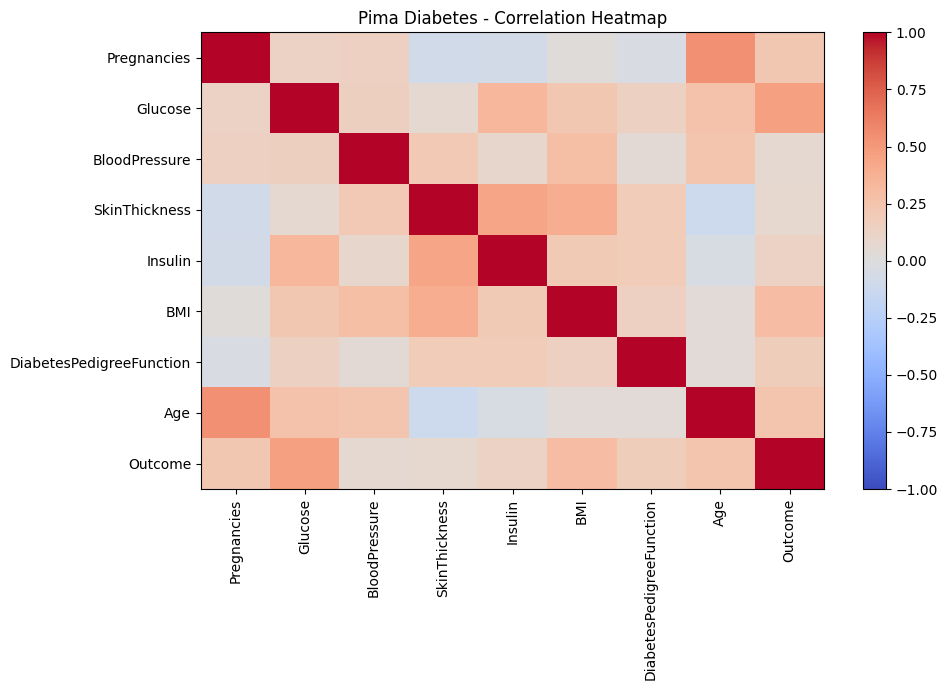

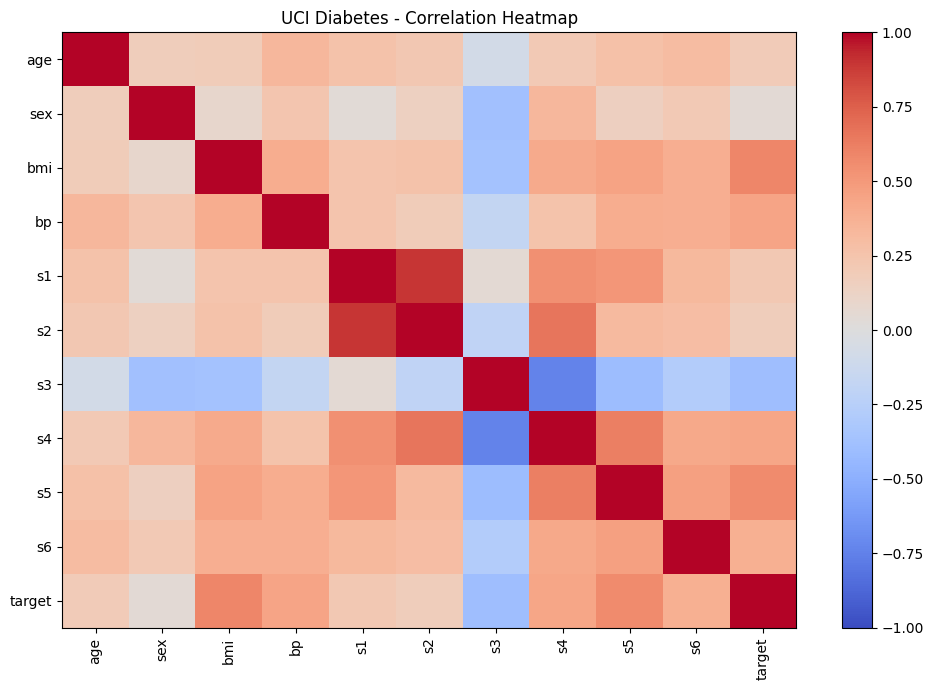

In [74]:
correlation_heatmap(pima_df, 'Pima Diabetes')
correlation_heatmap(uci_df, 'UCI Diabetes')

In [75]:
comparison_df = pd.DataFrame({
    'Analysis Metric': [
        'Number of Samples',
        'Number of Features',
        'Target Variable',
        'Target Type',
        'R2 Score',
        'Mean Squared Error'
    ],

    'Pima Indians Dataset': [
        len(pima_df),
        pima_df.shape[1] - 1,
        'Outcome',
        'Binary (0/1)',
        round(pima_r2, 4),
        round(pima_mse, 4)
    ],

    'UCI Diabetes Dataset': [
        len(uci_df),
        uci_df.shape[1] - 1,
        'target',
        'Continuous',
        round(uci_r2, 4),
        round(uci_mse, 4)
    ]
})

In [76]:
print("\n========== COMPARISON OF BOTH DATASETS ==========")
print(comparison_df.to_string(index=False))


========== COMPARISON OF BOTH DATASETS ==========
   Analysis Metric Pima Indians Dataset UCI Diabetes Dataset
 Number of Samples                  768                  442
Number of Features                    8                   10
   Target Variable              Outcome               target
       Target Type         Binary (0/1)           Continuous
          R2 Score                0.255               0.4526
Mean Squared Error                0.171            2900.1936
